# Q-Learning on MountainCar-v0
## Phases 1 and 2: Business Understanding · Data Acquisition & Understanding

**AML Project – ESPRIT 4DAS**

**Team:** Kawther Amri · Balkiss Youssfi · Loussaif Bhiri · Manar Fares · Yasmine Maatougui · Khairi Charrad

**Supervisor:** Wiem Trabelsi

**Project deliverables:** Python notebook, PDF report, PowerPoint presentation, README, references

Reference paper: *Modelling a Reinforcement Learning Agent For Mountain Car Problem Using Q-Learning With Tabular Discretization* (IEEE MysuruCon 2022)

---

### Project roadmap
| Phase | Content | Where |
|---|---|---|
| 1 | Business Understanding | this notebook |
| 2 | Data Acquisition & Understanding (MDP, environment, data collection) | this notebook |
| 3 | Data Preparation: state discretization | upcoming |
| 4 | Modeling: Q-Learning, comparison with SARSA | upcoming |
| 5 | Evaluation: criteria of section 1.5 | upcoming |

### How to read this notebook
Every chosen value is justified, either in a **Why?** note in the text or in a `# WHY` comment in the code. We always distinguish:
- values **imposed by the environment** (bounds, force, gravity, 200-step limit): they are **read from Gymnasium**, never copied by hand;
- values **chosen by the team** (γ, number of episodes, success thresholds, grid size): they are justified and may be revised.

---
# Phase 1: Business Understanding

## 1.1 Context

A car is placed at the bottom of a valley between two hills. It must reach a flag at the top of the right hill. Its engine is **too weak to drive straight up**: the only winning strategy is to first move left to build momentum, then accelerate to the right.

This problem, introduced by Moore (1990), is a classic reinforcement learning benchmark. It represents a family of real-world problems where:
- the right decision first goes **away from the goal** (sacrificing an immediate gain for a future one);
- the useful reward arrives **late**;
- nobody provides the correct answer: the agent must learn **by trial and error**.

**Application domains** of this type of problem: robotics (motor control), autonomous vehicles, energy management, games, system optimization.

## 1.2 Problem statement

> Build an agent that learns **on its own**, without knowing the physics of the car, a strategy that reaches the flag **as fast as possible**.

**Why reinforcement learning?**

| Learning type | Principle | Suitable here? |
|---|---|---|
| Supervised | learns from labelled data (correct answers known) | No: nobody knows the correct action in each state |
| Unsupervised | finds structure in unlabelled data | No: we need to make decisions, not group data |
| **Reinforcement** | learns through interaction, from rewards | **Yes**: the agent acts, observes the outcome and improves |

## 1.3 Business objectives

The business objectives answer the question **"what is it for, from the user's point of view?"**. MountainCar is a simulation, so we reason as if the car were a **real system to control** (for example a low-power robot or vehicle).

| # | Business objective | Description |
|---|---|---|
| BO1 | **Reliability** | the system reaches its goal at almost every attempt |
| BO2 | **Efficiency** | it gets there as fast as possible (less time, less energy) |
| BO3 | **Autonomy** | it discovers its strategy by itself, **without an engineer hand-coding the solution**; if the environment changes, we retrain instead of rewriting the controller |
| BO4 | **Reasonable cost** | training takes an acceptable time on a standard computer |
| BO5 | **Interpretability** | the learned strategy can be visualised and explained |

## 1.4 Data Science objectives

The Data Science objectives translate the business objectives into **technical goals** (how we achieve them).

| # | Data Science objective | Serves |
|---|---|---|
| DSO1 | Formulate the problem as a **Markov Decision Process** (states, actions, rewards, γ) | all |
| DSO2 | Collect and validate interaction data (transitions) and measure **baselines** | BO1, BO2 |
| DSO3 | Make the continuous state space usable by a table through **discretization** | BO3, BO4 |
| DSO4 | Implement a **tabular Q-Learning** agent with an **ε-greedy** exploration strategy | BO3 |
| DSO5 | Study the effect of hyperparameters (number of bins, α, γ, ε) | BO1, BO2 |
| DSO6 | Compare with **SARSA** and with the reference paper | BO1, BO2 |
| DSO7 | Visualise the learned policy (policy map) and the learning curves | BO5 |

**Link between business objectives, Data Science objectives and success criteria**

| Business objective | Data Science objective | Measured criterion (section 1.5) |
|---|---|---|
| BO1 Reliability | DSO4, DSO5: greedy evaluation (ε = 0) | success rate ≥ 90 % |
| BO2 Efficiency | DSO4: maximise the return (−1 per step) | mean reward > −160 |
| BO3 Autonomy | DSO3, DSO4: learning without a hand-written rule | gain ≥ 40 steps over the random agent |
| BO4 Reasonable cost | DSO3: tabular method | training time of minutes to one hour |
| BO5 Interpretability | DSO7: readable Q-table | policy map produced |

## 1.5 Success criteria

| Criterion | Measure | Target | Why this threshold? |
|---|---|---|---|
| Reliability | success rate over 100 test episodes, no exploration (ε = 0) | ≥ 90 % | team choice: an agent failing more than once in ten is not "reliable" |
| Speed | mean test reward (= − number of steps) | > −160 (fewer than 160 steps) | team choice: realistic intermediate goal for a discretized table. Gymnasium's official "solved" threshold is stricter; it is **read and displayed** in 2.B.2 |
| Gain over the baseline | mean reward of the trained agent − that of the random agent | ≥ 40 steps | follows from the two lines above: (−160) − (−200) = 40 |
| Convergence | first episode where the moving average **over 100 episodes** exceeds −160 | reached before the end of training | the 100-episode window is the one used by Gymnasium's official criterion |
| Reproducibility | standard deviation of the mean test reward over **5 seeds** | < 10 steps | team choice: 5 seeds = trade-off between compute time and reliability of the estimate |
| Position relative to a simple heuristic | mean reward vs the "push in the direction of the velocity" policy | indicative | this hand-written rule gives a realistic bound; it is measured in 2.C.4 |

> These thresholds are **team choices** (not taken from the paper): they are to be validated with the supervisor.

The **baseline** to beat is an agent choosing its actions at random; it is measured in 2.C.4.

## 1.6 Constraints, assumptions and risks

**Constraints**
- Imposed method: **tabular** Q-Learning (no neural network).
- Resources: a personal computer; training must stay within minutes to one hour.
- An episode is limited to **200 steps** (value imposed by the environment).

**Assumptions**
- The Gymnasium environment is a faithful and reproducible simulation of the problem. *Verified in 2.B.3.*
- A regular discretization of the state space is enough to learn a good policy. *To be tested in phase 3.*

**Identified risks**

| Risk | Consequence | Planned response |
|---|---|---|
| Very sparse reward (the random agent almost never reaches the flag) | no learning signal at the beginning | optimistic initialization of Q, well-tuned exploration |
| Discretization too coarse or too fine | imprecise policy or very slow learning | experiment on the number of bins |
| Unstable learning | oscillating performance | separate evaluation, several seeds |
| Results depending on randomness | fragile conclusions | fixed seeds, robustness test |

> **Why does optimistic initialization of Q work here?** Every step costs −1, so all true Q-values are **negative**. If the table is initialised to 0, every untried action looks better than it really is. Once an action is tried, its value drops and it becomes less attractive than untried actions: the agent therefore explores **systematically**, even with ε = 0, without relying on chance.

## 1.7 State of the art

**The benchmark.** The Mountain Car problem was introduced by Moore (1990) and popularised by Sutton & Barto, *Reinforcement Learning: An Introduction*. It is a reference benchmark because it combines a **continuous state space** with a **sparse, delayed reward**: a random policy almost never reaches the goal.

**Tabular temporal-difference methods.**
- **Q-Learning** (Watkins & Dayan, 1992) is an *off-policy* TD control method: it learns the value of the greedy (optimal) policy while following an exploratory one.
- **SARSA** (Rummery & Niranjan, 1994) is the *on-policy* counterpart: it updates with the action actually taken.
- Both require a finite state space; on Mountain Car the continuous state must therefore be **discretized** into a grid. This is the approach of our reference paper (MysuruCon 2022), which shows that a tabular agent on a regular grid can learn the swinging strategy.

**Function approximation.** To avoid the limits of a fixed grid, several works approximate the value function instead of tabulating it:
- **Tile coding / CMAC** (coarse coding with several overlapping offset grids) was shown to learn Mountain Car efficiently with SARSA (Sutton, 1996) and is the standard approach in Sutton & Barto (2018, chapter 10).
- Boyan & Moore (1995) showed that combining TD learning with some function approximators can become **unstable** on this type of problem: a reason why simple, well-understood representations are often preferred.
- **Deep Q-Networks** (Mnih et al., 2015) replace the table with a neural network and remove the need for discretization; on Mountain Car they still suffer from the sparse reward and usually need careful exploration.

**Exploration.** Because of the sparse reward, exploration is the central difficulty. Classical answers are ε-greedy schedules, **optimistic initialization** of the value function and, in more recent work, exploration bonuses or reward shaping.

**Positioning of our project.** We follow the tabular approach of the reference paper (Q-Learning + regular discretization) and add: a systematic study of the hyperparameters (number of bins, α, γ, ε), a greedy evaluation separated from training, a comparison with SARSA, a robustness test over several seeds and a comparison with a hand-written heuristic.

| Approach | State representation | Main advantage | Main limit |
|---|---|---|---|
| Tabular Q-Learning / SARSA (our choice) | regular grid | simple, interpretable, guaranteed convergence in the tabular case | grid size grows quickly; loss of information |
| Tile coding + SARSA | several overlapping grids | better generalisation between neighbouring states | more parameters to tune |
| Deep Q-Network | neural network | no discretization, scales to large state spaces | less stable, less interpretable, more compute |

---
# Phase 2: Data Acquisition & Understanding

In reinforcement learning there is **no given dataset**: the data are transitions (state, action, reward, next state) **generated through the interaction** of the agent with the environment. This phase has three parts:
- **2.A** Data Understanding: formulating the problem as an MDP;
- **2.B** Data Acquisition: setting up and understanding the environment (the data source);
- **2.C** Data Acquisition & Exploration: collecting, checking and exploring the transitions.

---
## 2.A Data Understanding: MDP formulation

This step translates the problem into mathematical language: a **Markov Decision Process** (MDP).

### 2.A.0 Components of the RL system

| Component | Definition | MountainCar-v0 |
|---|---|---|
| **Agent** | the learner and decision maker | the car controller |
| **Environment** | the world the agent acts in | the valley and the car physics |
| **State (s)** | the current situation | (position, velocity) |
| **Action (a)** | what the agent can do | push left, do nothing, push right |
| **Reward (r)** | feedback signal after an action | −1 at each step |
| **Policy (π)** | the agent's strategy to choose actions | what the agent must learn |

**Agent's objective**: *maximise the cumulative reward over time.*

### 2.A.1 The MDP: (S, A, P, R, γ) and the initial distribution μ₀

| Element | Meaning | MountainCar-v0 | Why this value? |
|---|---|---|---|
| **S** | set of states | s = (x, v), x ∈ [−1.2, 0.6], v ∈ [−0.07, 0.07]: **continuous** | bounds imposed by Gymnasium; two variables are enough to describe the future (Markov property, 2.A.3) |
| **A** | set of actions | {0: push left, 1: do nothing, 2: push right}: **discrete** | defined by the environment: 3 actions |
| **P(s′ \| s, a)** | transition probability | the car physics: **deterministic**, but **unknown to the agent** | this is what requires a *model-free* method (2.A.5) |
| **R(s, a, s′)** | reward | −1 at each step, **including the step that reaches the flag** | turns "go fast" into the objective: more steps means a lower total |
| **γ** | weight of future rewards | 0.99 | **team choice**, justified in 2.A.4 |
| **μ₀** | initial state distribution | x ~ Uniform[−0.6, −0.4], v = 0 | the only **random** element of the environment; checked in 2.C.2 |

### 2.A.2 Episodes, terminal states and truncation

- **Episode start**: x drawn at random in [−0.6, −0.4], zero velocity (μ₀).
- **Terminal state (success)**: the flag is reached, i.e. **x ≥ 0.5 AND v ≥ 0**. In Gymnasium the full condition is `position >= goal_position and velocity >= goal_velocity` with `goal_velocity = 0`. The velocity condition hardly changes anything in practice, but the exact rule must be stated.
- **Truncation (failure)**: the episode is cut after **200 steps** without reaching the flag. This is **not** a terminal state of the MDP: it is a time limit imposed from outside. The difference matters for the Q update (see 2.A.7).
- **Episode return**: since each step costs −1, the undiscounted return equals **− (number of steps)**. Maximising the reward therefore means **reaching the flag as fast as possible**.

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots$$

### 2.A.3 Markov property and full dynamics

*The future state depends only on the current state and action, not on past states.* Gymnasium implements the following dynamics, in this order:

1. $v_{t+1} = v_t + (a_t - 1)\times F - \cos(3\,x_t)\times g$, with $F = 0.001$ (engine force) and $g = 0.0025$ (gravity);
2. the velocity is **clipped**: $v_{t+1} \in [-0.07,\ 0.07]$;
3. $x_{t+1} = x_t + v_{t+1}$, then the position is **clipped**: $x_{t+1} \in [-1.2,\ 0.6]$;
4. **left wall**: if $x_{t+1} = -1.2$ and $v_{t+1} < 0$, then $v_{t+1} = 0$ (the car hits the wall and stops).

Position x and velocity v are enough: the history is useless. The state (x, v) is therefore **Markovian**.

**Why the term −cos(3x) × g?** The terrain height is $\sin(3x)$ and its slope is $3\cos(3x)$: gravity pulling the car along the slope is proportional to $\cos(3x)$. It is maximal (in absolute value) at x = 0 and zero at the tops of the slope.

**Why can't the car drive straight up?** The engine force ($F = 0.001$) is weaker than the maximal effect of gravity ($g = 0.0025$). The code in 2.B.2 checks this from the constants read in the environment.

**Two caveats about the Markov property**
- The 200-step limit introduces a dependence on the **remaining time**, which is not part of the state (x, v). This is a standard approximation in reinforcement learning.
- After discretization (phase 3), two different continuous states will fall into the same cell: the Markov property will only hold **approximately**. This must be discussed in the analysis of the results.

### 2.A.4 Choice of γ

**Idea.** γ sets how far ahead the agent "sees" the consequences of its actions: the **effective horizon** is about $1/(1-\gamma)$ steps. Reaching the flag takes one to two hundred steps (the heuristic of 2.C.4 does it in about a hundred steps): we need a horizon of that order.

**A sharper argument than the weight γᵏ.** Since each step costs −1, the discounted return of an n-step episode is

$$G = -\sum_{k=0}^{n-1}\gamma^k = -\frac{1-\gamma^n}{1-\gamma}$$

For small γ this return **saturates** at $-1/(1-\gamma)$ whatever n: the agent can no longer tell a short trajectory from a long one, so it has no reason to hurry. The table below shows it.

In [1]:
# WHY this cell: compare three values of γ on the criterion that really matters,
# i.e. the ability to distinguish a 100-step trajectory from a 200-step one.
import numpy as np
import pandas as pd

GAMMAS = [0.9, 0.95, 0.99]


def discounted_return(gamma, n):
    # Geometric sum of n rewards of -1: -(1 - γ^n) / (1 - γ)
    return -(1 - gamma ** n) / (1 - gamma)


rows = []
for g in GAMMAS:
    rows.append({
        "γ": g,
        "effective horizon 1/(1-γ)": round(1 / (1 - g)),
        "weight of a reward 100 steps ahead (γ^100)": g ** 100,
        "return of a 100-step trajectory": discounted_return(g, 100),
        "return of a 200-step trajectory": discounted_return(g, 200),
        "gap 200 steps - 100 steps": discounted_return(g, 200) - discounted_return(g, 100),
    })
gamma_table = pd.DataFrame(rows).round(4)
gamma_table

,γ,effective horizon 1/(1-γ),weight of a reward 100 steps ahead (γ^100),return of a 100-step trajectory,return of a 200-step trajectory,gap 200 steps - 100 steps
0,0.90,10,0.0000,-9.9997,-10.0000,-0.0003
1,0.95,20,0.0059,-19.8816,-19.9993,-0.1177
2,0.99,100,0.3660,-63.3968,-86.6020,-23.2053


**Reading and decision.**
- γ = 0.9: horizon of about 10 steps and almost no gap between a short and a long trajectory → unsuitable.
- γ = 0.95: horizon of about 20 steps, gap still very small → insufficient.
- **γ = 0.99**: horizon of about 100 steps, clear gap between the two trajectories → selected.

γ = 1 would also be possible (allowed because episodes are finite), but γ < 1 stabilises tabular learning. The choice 0.99 will be **tested** in the hyperparameter analysis (DSO5).

### 2.A.5 Consequences for the choice of method

| Observation | Consequence |
|---|---|
| P is **unknown** to the agent | **Dynamic Programming** (Policy Iteration / Value Iteration) requires a full model → **model-free** method |
| Episodes can be long (200 steps) | a **Temporal Difference** method (update after each transition, by bootstrapping) is preferable to Monte Carlo, which waits for the end of the episode |
| Actions are discrete (3) | a table Q(s, a) is possible on the action side |
| States are **continuous** | a **discretization** of the states is needed to use a table (phase 3) |
| We look for the optimal policy | **Q-Learning** (off-policy), compared with **SARSA** (on-policy) |

### 2.A.6 Policy and Bellman equations

**Policy**: it maps each state to a distribution over actions.

$$\pi(a \mid s) = P(\text{take action } a \text{ in state } s)$$

A **deterministic** policy picks one action per state; a **stochastic** policy gives a probability to each action. The ε-greedy policy used during learning is stochastic; the final learned policy is deterministic.

**Bellman expectation equation for V** *(value of a state under π = immediate reward + discounted value of the next state)*:

$$V^{\pi}(s) = \sum_a \pi(a \mid s) \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma V^{\pi}(s')\right]$$

**Bellman expectation equation for Q**:

$$Q^{\pi}(s,a) = \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma \sum_{a'} \pi(a' \mid s')\,Q^{\pi}(s',a')\right]$$

**Bellman optimality equation for Q** *(the one Q-Learning tries to satisfy; the `max` replaces the sum over the policy)*:

$$Q^*(s,a) = \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma \max_{a'} Q^*(s',a')\right], \qquad \pi^*(s) = \arg\max_a Q^*(s,a)$$

**Special case of MountainCar.** The environment is deterministic: $s' = f(s,a)$ and $R = -1$. The sum over s′ disappears:

$$Q^*(s,a) = -1 + \gamma \max_{a'} Q^*\big(f(s,a),a'\big)$$

(with $Q^* = 0$ from a terminal state). The expectation of the general formulation is therefore unnecessary here, but it remains valid.

In MountainCar, $P$ is **unknown** to the agent: these sums cannot be computed directly (limit of dynamic programming). The model-free method learns Q **from the observed transitions** $(s_t, a_t, r_{t+1}, s_{t+1})$.

### 2.A.7 Consequence for the Q update: `terminated` ≠ `truncated`

For a transition $(s, a, r, s')$, the Q-Learning rule is:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\, r + \gamma\,(1-d)\,\max_{a'}Q(s',a') - Q(s,a)\Big]$$

with $d = 1$ **only if `terminated` is true**.

**Why not set d = 1 when the episode is truncated?** A truncation is not a real end: if the episode had continued, the car would have collected more −1. Setting $d=1$ would tell the agent that the state reached at step 200 is worth 0, i.e. **better than all true (negative) values**: this would introduce an artificial optimistic bias. We therefore keep using $\max_{a'} Q(s',a')$ on truncation.

(For SARSA, $\max_{a'}Q(s',a')$ is replaced by $Q(s',a')$ where $a'$ is the action actually chosen: this is the only difference, studied in phase 4.)

This is why the dataset keeps **two separate columns**, `terminated` and `truncated`.

---
## 2.B Data Acquisition: the environment as data source

The environment is the **data source** of the project.

### 2.B.1 Installation, imports and project parameters

Run once if needed:
```
pip install "gymnasium[classic_control]" numpy pandas matplotlib
```
The next cell also writes a `requirements.txt` with the **versions actually used**, so that the project is reproducible on another machine.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym

# ---------------------------------------------------------------------------------------------
# Project parameters: all team choices are grouped here and commented.
# ---------------------------------------------------------------------------------------------
ENV_ID = "MountainCar-v0"

SEED = 42
# WHY 42: conventional value. Only FIXING the seed matters: it makes results reproducible.
# All randomness goes through (1) env.reset(seed=...) for the initial state and
# (2) a generator np.random.default_rng(seed) for random actions.
# The global generator (np.random.seed) is therefore never used.

N_EPISODES = 100
# WHY 100: it is the size of the window of Gymnasium's official criterion (mean over
# 100 episodes). 100 episodes x 200 steps give at most 20,000 transitions: enough to
# explore the environment, in a few seconds of computation.

GRID = 20
# WHY 20: a 20 x 20 grid = 400 cells, used here ONLY to measure the coverage of the
# state space. It is a working value; the actual number of bins will be chosen
# experimentally in phase 3 (discretization).

TOL = 1e-5
# WHY 1e-5: Gymnasium returns float32 values (relative precision ~ 1.2e-7). Values stay
# below 1.2 in absolute value, so the expected rounding error is about 1e-7. A tolerance
# of 1e-5 leaves a margin of about 100 without hiding a real error.

os.makedirs("data", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

# Versions used, saved for reproducibility
versions = {"gymnasium": gym.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, "matplotlib": matplotlib.__version__}
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(f"gymnasium[classic_control]=={versions['gymnasium']}\n")
    for name in ("numpy", "pandas", "matplotlib"):
        f.write(f"{name}=={versions[name]}\n")
print("Versions:", versions)

Versions: {'gymnasium': '1.4.0', 'numpy': '2.5.3', 'pandas': '3.0.5', 'matplotlib': '3.11.2'}


### 2.B.2 Creating and inspecting the environment

The physical constants are **read from the environment** (instead of being copied): the notebook stays correct even if a Gymnasium version changes one of them.

In [3]:
env = gym.make(ENV_ID)
u = env.unwrapped   # access to the "raw" environment, which holds the physical constants

# Constants imposed by the environment (read, never copied by hand)
ENV_CONST = {
    "force": u.force,                    # engine power
    "gravity": u.gravity,                # gravity strength
    "min_position": u.min_position,      # left wall
    "max_position": u.max_position,      # right bound
    "max_speed": u.max_speed,            # maximal absolute velocity
    "goal_position": u.goal_position,    # flag position
    "goal_velocity": u.goal_velocity,    # minimal velocity required at the flag
}
low, high = env.observation_space.low.copy(), env.observation_space.high.copy()
MAX_STEPS = env.spec.max_episode_steps          # episode limit
REWARD_THRESHOLD = env.spec.reward_threshold    # official "solved" threshold

print("Environment id         :", env.spec.id)
print("Episode limit          :", MAX_STEPS, "steps")
print("Official solved thresh.:", REWARD_THRESHOLD, "(mean reward over 100 episodes)")
print("Observation space      :", env.observation_space)
print("  lower bounds         :", low, "(position, velocity)")
print("  upper bounds         :", high)
print("Action space           :", env.action_space, "→ 0 = left, 1 = nothing, 2 = right")
print("Physical constants     :", ENV_CONST)

# Check of the argument of 2.A.3: the engine is weaker than maximal gravity
print("\nEngine force < maximal gravity?", ENV_CONST["force"] < ENV_CONST["gravity"],
      f"({ENV_CONST['force']} < {ENV_CONST['gravity']}) → the car cannot drive straight up")

state, info = env.reset(seed=SEED)
print("\nInitial state (position, velocity):", state)

# One transition, to see the shape of the data
next_state, reward, terminated, truncated, info = env.step(2)
print("After action 2 (right):", next_state, "| reward:", reward,
      "| terminated:", terminated, "| truncated:", truncated)
env.close()

Environment id         : MountainCar-v0
Episode limit          : 200 steps
Official solved thresh.: -110.0 (mean reward over 100 episodes)
Observation space      : Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
  lower bounds         : [-1.2  -0.07] (position, velocity)
  upper bounds         : [0.6  0.07]
Action space           : Discrete(3) → 0 = left, 1 = nothing, 2 = right
Physical constants     : {'force': 0.001, 'gravity': 0.0025, 'min_position': -1.2, 'max_position': 0.6, 'max_speed': 0.07, 'goal_position': 0.5, 'goal_velocity': 0}

Engine force < maximal gravity? True (0.001 < 0.0025) → the car cannot drive straight up

Initial state (position, velocity): [-0.4452088  0.       ]
After action 2 (right): [-4.4479132e-01  4.1747934e-04] | reward: -1.0 | terminated: False | truncated: False


### 2.B.3 Checking the dynamics (Markov property)

We check that the next state returned by Gymnasium matches the full formula of 2.A.3 (**with** clipping and left wall), and that the success rule `terminated` is the one of 2.A.2.

**Why test several policies and episodes?** A single random episode stays in the central part of the valley and never tests the edge cases (wall, maximal velocity). We therefore add:
- an **"always left"** policy, which explores the left slope;
- a **"follow the velocity"** policy (push in the direction of motion), which builds momentum, can hit the left wall and reaches the flag: it therefore tests the success condition.

The table shows, for each policy, **how many steps actually hit the left wall**: if this number is zero, the edge case was not exercised by that policy.

In [4]:
def dynamics(x, v, a, c=ENV_CONST):
    # Reproduces the physics of 2.A.3, in the same order as Gymnasium.
    v2 = v + (a - 1) * c["force"] - np.cos(3 * x) * c["gravity"]
    v2 = np.clip(v2, -c["max_speed"], c["max_speed"])                # velocity clipping
    x2 = np.clip(x + v2, c["min_position"], c["max_position"])       # position clipping
    if x2 == c["min_position"] and v2 < 0:                           # left wall
        v2 = 0.0
    # FULL success condition: position AND velocity
    terminated = bool(x2 >= c["goal_position"] and v2 >= c["goal_velocity"])
    return x2, v2, terminated


# Three simple policies, used here and for the baseline (2.C.4)
def random_policy(state, rng):
    return int(rng.integers(3))          # 0, 1 or 2 with equal probability


def left_policy(state, rng):
    return 0                             # always push left


def velocity_policy(state, rng):
    return 2 if state[1] >= 0 else 0     # push in the direction of the current velocity


def check_dynamics(policy, n_episodes=20, seed=SEED):
    rng = np.random.default_rng(seed)
    env = gym.make(ENV_ID)
    max_gap, n_steps, n_wall, n_mismatch = 0.0, 0, 0, 0
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done = False
        while not done:
            a = policy(state, rng)
            x2, v2, expected_terminated = dynamics(float(state[0]), float(state[1]), a)
            state, _, terminated, truncated, _ = env.step(a)
            max_gap = max(max_gap, abs(state[0] - x2), abs(state[1] - v2))
            n_mismatch += int(terminated != expected_terminated)
            n_wall += int(x2 == ENV_CONST["min_position"])
            n_steps += 1
            done = terminated or truncated
    env.close()
    return {"steps tested": n_steps, "max gap": max_gap,
            "steps against left wall": n_wall, "success-rule mismatches": n_mismatch}


results = {name: check_dynamics(pol) for name, pol in
           [("random", random_policy), ("always left", left_policy),
            ("follow velocity", velocity_policy)]}
check = pd.DataFrame(results).T
display_table = check.copy()
display_table["max gap"] = check["max gap"].map(lambda z: f"{z:.2e}")
for col in ["steps tested", "steps against left wall", "success-rule mismatches"]:
    display_table[col] = check[col].astype(int)
print(display_table.to_string())

ok = (check["max gap"] < TOL).all() and (check["success-rule mismatches"] == 0).all()
print("\n→ deterministic and Markovian dynamics confirmed" if ok else "\n→ unexpected gap: to be analysed")

                 steps tested   max gap  steps against left wall  success-rule mismatches
random                   4000  5.86e-08                        0                        0
always left              4000  5.85e-08                        0                        0
follow velocity          2395  1.12e-07                        8                        0



→ deterministic and Markovian dynamics confirmed


### 2.B.4 The terrain: shape of the hill

The terrain height is sin(3x). The plot shows the valley, the start zone, the left wall and the flag.

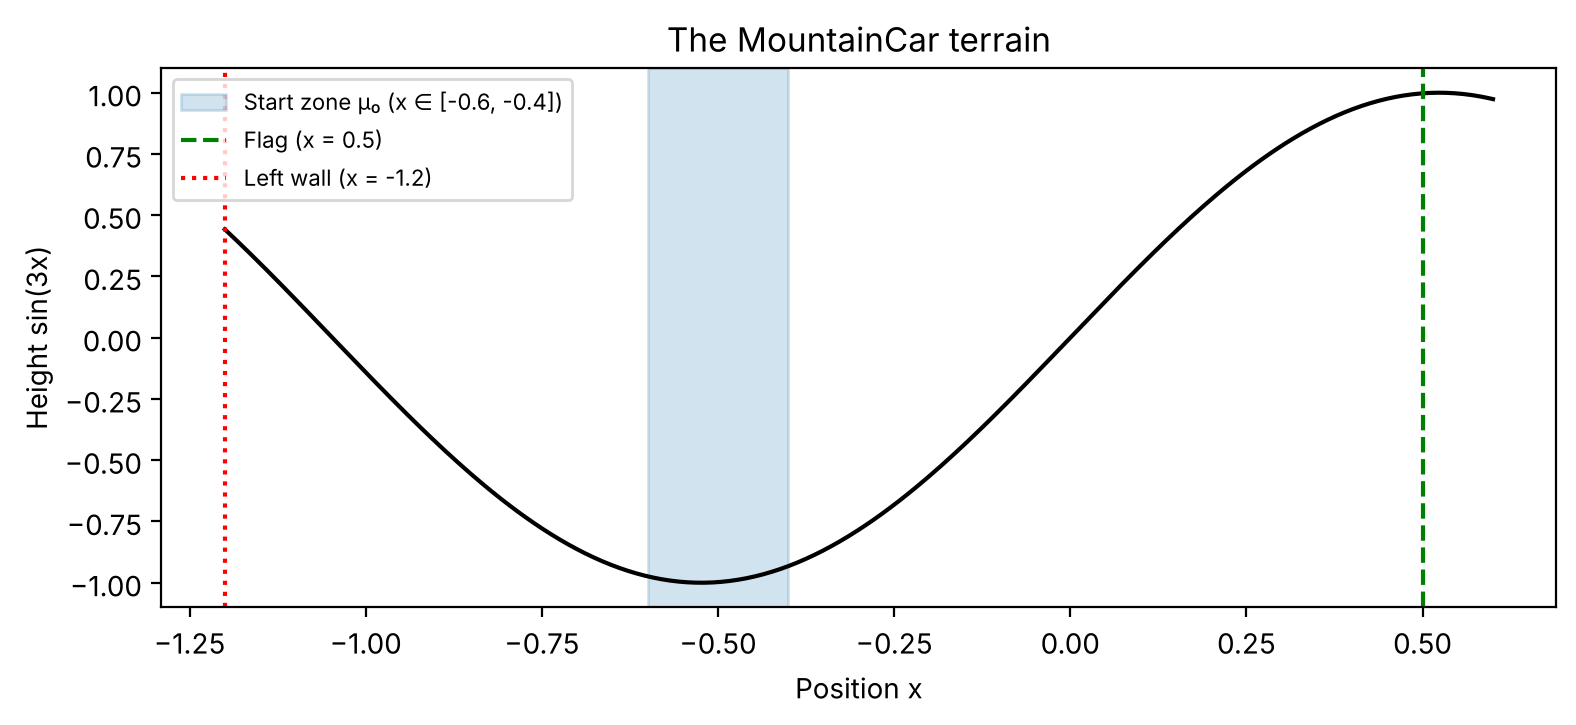

In [5]:
x = np.linspace(ENV_CONST["min_position"], ENV_CONST["max_position"], 300)
plt.figure(figsize=(9, 3.5))
plt.plot(x, np.sin(3 * x), color="black")
plt.axvspan(-0.6, -0.4, color="tab:blue", alpha=0.2, label="Start zone μ₀ (x ∈ [-0.6, -0.4])")
plt.axvline(ENV_CONST["goal_position"], color="green", linestyle="--",
            label=f"Flag (x = {ENV_CONST['goal_position']})")
plt.axvline(ENV_CONST["min_position"], color="red", linestyle=":", label="Left wall (x = -1.2)")
plt.xlabel("Position x")
plt.ylabel("Height sin(3x)")
plt.title("The MountainCar terrain")
plt.legend(fontsize=8)
plt.savefig("results/figures/terrain.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.B.5 Data dictionary

| Variable | Type | Domain | Description |
|---|---|---|---|
| `policy` | text | {random, velocity} | policy that generated the transition |
| `episode` | integer | 0 … N−1 | episode number |
| `step` | integer | 0 … 199 | step number within the episode |
| `position` | real | [−1.2, 0.6] | car position **before** the action |
| `velocity` | real | [−0.07, 0.07] | car velocity **before** the action |
| `action` | integer | {0, 1, 2} | chosen action |
| `reward` | real | constant = −1 | reward received (also at the terminal step) |
| `next_position` | real | [−1.2, 0.6] | position **after** the action |
| `next_velocity` | real | [−0.07, 0.07] | velocity **after** the action |
| `terminated` | boolean | — | flag reached: position ≥ 0.5 **and** velocity ≥ 0 |
| `truncated` | boolean | — | 200-step limit reached (≠ terminal state, see 2.A.7) |

---
## 2.C Data Acquisition & Exploration: collecting transitions

Each interaction produces a **transition**:

$$(s_t,\ a_t,\ r_{t+1},\ s_{t+1},\ \text{done})$$

We collect transitions with a **random agent**, check their quality, measure the **baseline** to beat (random agent, plus a simple heuristic) and save the dataset.

### 2.C.1 Collecting transitions

The random agent plays `N_EPISODES` episodes and every transition is recorded. These data are used to understand the environment and to measure the baseline; the Q-Learning agent will later generate its own data during training.

We also collect the transitions of the **"follow the velocity"** policy: this is **not** the goal of the project (we want an agent that learns without a hand-written rule), but it gives a realistic reference of what can be achieved.

In [6]:
def collect(policy, name, n_episodes=N_EPISODES, seed=SEED):
    # WHY one rng for the actions and env.reset(seed=seed+ep) for the initial state:
    # each episode has its own reproducible initial state, and the sequence of random
    # actions is reproducible too. Two sources of randomness, two controlled seeds.
    env = gym.make(ENV_ID)
    rng = np.random.default_rng(seed)
    rows = []
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done, step = False, 0
        while not done:
            action = policy(state, rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            rows.append({
                "policy": name, "episode": ep, "step": step,
                "position": float(state[0]), "velocity": float(state[1]),
                "action": action, "reward": reward,
                "next_position": float(next_state[0]), "next_velocity": float(next_state[1]),
                "terminated": terminated, "truncated": truncated,
            })
            state, step = next_state, step + 1
            done = terminated or truncated
    env.close()
    return pd.DataFrame(rows)


df = collect(random_policy, "random")
df_velocity = collect(velocity_policy, "velocity")
print("Random agent     :", len(df), "transitions |", df["episode"].nunique(), "episodes")
print("Follow velocity  :", len(df_velocity), "transitions |", df_velocity["episode"].nunique(), "episodes")
df.head()

Random agent     : 20000 transitions | 100 episodes
Follow velocity  : 12019 transitions | 100 episodes


,policy,episode,step,position,velocity,action,reward,next_position,next_velocity,terminated,truncated
0,random,0,0,-0.445209,0.000000,0,-1.0,-0.446791,-0.001583,False,False
1,random,0,1,-0.446791,-0.001583,2,-1.0,-0.447945,-0.001153,False,False
2,random,0,2,-0.447945,-0.001153,1,-1.0,-0.449661,-0.001716,False,False
3,random,0,3,-0.449661,-0.001716,1,-1.0,-0.451927,-0.002266,False,False
4,random,0,4,-0.451927,-0.002266,1,-1.0,-0.454726,-0.002799,False,False


### 2.C.2 Data quality checks

We check not only the bounds but also the **internal consistency** of the dataset (continuity between transitions, initial state, success rule).

In [7]:
def quality_checks(d):
    eps = 1e-6   # WHY: tolerance on the bounds, because Gymnasium bounds are float32
    last_step = d.groupby("episode").cumcount(ascending=False) == 0
    prev_pos = d.groupby("episode")["next_position"].shift(1)
    prev_vel = d.groupby("episode")["next_velocity"].shift(1)
    steps_per_episode = d.groupby("episode")["step"].count()
    start = d[d["step"] == 0]

    return {
        "No missing values": d.isna().sum().sum() == 0,
        "Positions within bounds (before and after)":
            d[["position", "next_position"]].stack().between(low[0] - eps, high[0] + eps).all(),
        "Velocities within bounds (before and after)":
            d[["velocity", "next_velocity"]].stack().between(low[1] - eps, high[1] + eps).all(),
        "Actions in {0, 1, 2}": d["action"].isin([0, 1, 2]).all(),
        "Reward always -1 (including the terminal step)": (d["reward"] == -1).all(),
        f"At most {MAX_STEPS} steps per episode": steps_per_episode.max() <= MAX_STEPS,
        "Initial state: x in [-0.6, -0.4] and v = 0":
            start["position"].between(-0.6 - eps, -0.4 + eps).all() and (start["velocity"] == 0).all(),
        "Continuity: the end state of a step is the start state of the next":
            bool(((d["position"] - prev_pos).abs().dropna() < 1e-9).all()
                 and ((d["velocity"] - prev_vel).abs().dropna() < 1e-9).all()),
        "Success (terminated) ⇒ x ≥ 0.5 and v ≥ 0":
            bool(((d.loc[d["terminated"], "next_position"] >= ENV_CONST["goal_position"] - eps).all())
                 and ((d.loc[d["terminated"], "next_velocity"] >= ENV_CONST["goal_velocity"] - eps).all())),
        "Each episode ends with terminated or truncated, and never before":
            bool((d.loc[last_step, ["terminated", "truncated"]].any(axis=1)).all()
                 and not d.loc[~last_step, ["terminated", "truncated"]].any(axis=None)),
        "truncated only at the last allowed step":
            bool((d.loc[d["truncated"], "step"] == MAX_STEPS - 1).all()),
    }


for df_name, d in [("random", df), ("follow velocity", df_velocity)]:
    print(f"--- Checks for policy: {df_name} ---")
    for name, ok in quality_checks(d).items():
        print(("✅ " if ok else "❌ ") + name)
    print()

print(df.dtypes)

--- Checks for policy: random ---
✅ No missing values
✅ Positions within bounds (before and after)
✅ Velocities within bounds (before and after)
✅ Actions in {0, 1, 2}
✅ Reward always -1 (including the terminal step)
✅ At most 200 steps per episode
✅ Initial state: x in [-0.6, -0.4] and v = 0
✅ Continuity: the end state of a step is the start state of the next
✅ Success (terminated) ⇒ x ≥ 0.5 and v ≥ 0
✅ Each episode ends with terminated or truncated, and never before
✅ truncated only at the last allowed step

--- Checks for policy: follow velocity ---
✅ No missing values
✅ Positions within bounds (before and after)
✅ Velocities within bounds (before and after)
✅ Actions in {0, 1, 2}
✅ Reward always -1 (including the terminal step)
✅ At most 200 steps per episode
✅ Initial state: x in [-0.6, -0.4] and v = 0
✅ Continuity: the end state of a step is the start state of the next
✅ Success (terminated) ⇒ x ≥ 0.5 and v ≥ 0
✅ Each episode ends with terminated or truncated, and never before
✅ 

In [8]:
df[["position", "velocity", "next_position", "next_velocity"]].describe().round(4)

,position,velocity,next_position,next_velocity
count,20000.0000,20000.0000,20000.0000,20000.0000
mean,-0.5266,-0.0003,-0.5268,-0.0003
std,0.0845,0.0071,0.0847,0.0071
min,-0.9051,-0.0303,-0.9051,-0.0303
25%,-0.5803,-0.0048,-0.5805,-0.0048
50%,-0.5254,-0.0004,-0.5257,-0.0004
75%,-0.4729,0.0042,-0.4732,0.0042
max,-0.2060,0.0274,-0.2060,0.0274


### 2.C.3 Reading the descriptive statistics
The statistics above show the range actually explored by the random agent, to be compared with the bounds of the environment (position [−1.2, 0.6], velocity [−0.07, 0.07]). The gap between the two is the first sign of the difficulty of the problem: **an agent acting at random stays in a small area around its starting point**. Section 2.C.5 quantifies this coverage.

### 2.C.4 Baselines: random agent and "follow the velocity" heuristic

Two references:
- the **random agent**: the "no intelligence" level to beat (criterion "gain over the baseline");
- the **"follow the velocity" heuristic**: a hand-written rule that shows what is achievable. It is a **benchmark**, not a goal.

**Why add a second reference?** The random agent probably gets the same reward in every episode (zero standard deviation): it measures neither variability nor whether the −160 target is realistic. The heuristic bounds the goal from above.

In [9]:
def episode_summary(d):
    return d.groupby(["policy", "episode"]).agg(
        reward=("reward", "sum"),
        steps=("step", "count"),
        success=("terminated", "any"),
        max_position=("next_position", "max"),   # next_position: includes the last step
    ).reset_index()


episodes_all = episode_summary(pd.concat([df, df_velocity], ignore_index=True))

baselines = episodes_all.groupby("policy").agg(
    mean_reward=("reward", "mean"),
    std_reward=("reward", "std"),
    success_rate=("success", "mean"),
    mean_steps=("steps", "mean"),
    max_position=("max_position", "max"),
).round(3)
print(baselines.to_string())
print(f"\nGymnasium official 'solved' threshold: {REWARD_THRESHOLD}")
print("Action distribution of the random agent:")
print(df["action"].value_counts(normalize=True).sort_index()
      .rename({0: "left", 1: "nothing", 2: "right"}).round(3).to_string())

episodes = episodes_all[episodes_all["policy"] == "random"]   # used in the summary

          mean_reward  std_reward  success_rate  mean_steps  max_position
policy                                                                   
random        -200.00       0.000           0.0      200.00        -0.206
velocity      -120.19       3.234           1.0      120.19         0.543

Gymnasium official 'solved' threshold: -110.0
Action distribution of the random agent:
action
left       0.337
nothing    0.335
right      0.327


### 2.C.5 Coverage of the state space

We measure which share of the `GRID` × `GRID` grid (400 cells) is visited by each policy, using `np.histogram2d`, which counts exactly the cells of the grid.

Random agent    : 62 cells visited out of 400 (15.5 %)
Follow velocity : 136 cells visited out of 400 (34.0 %)


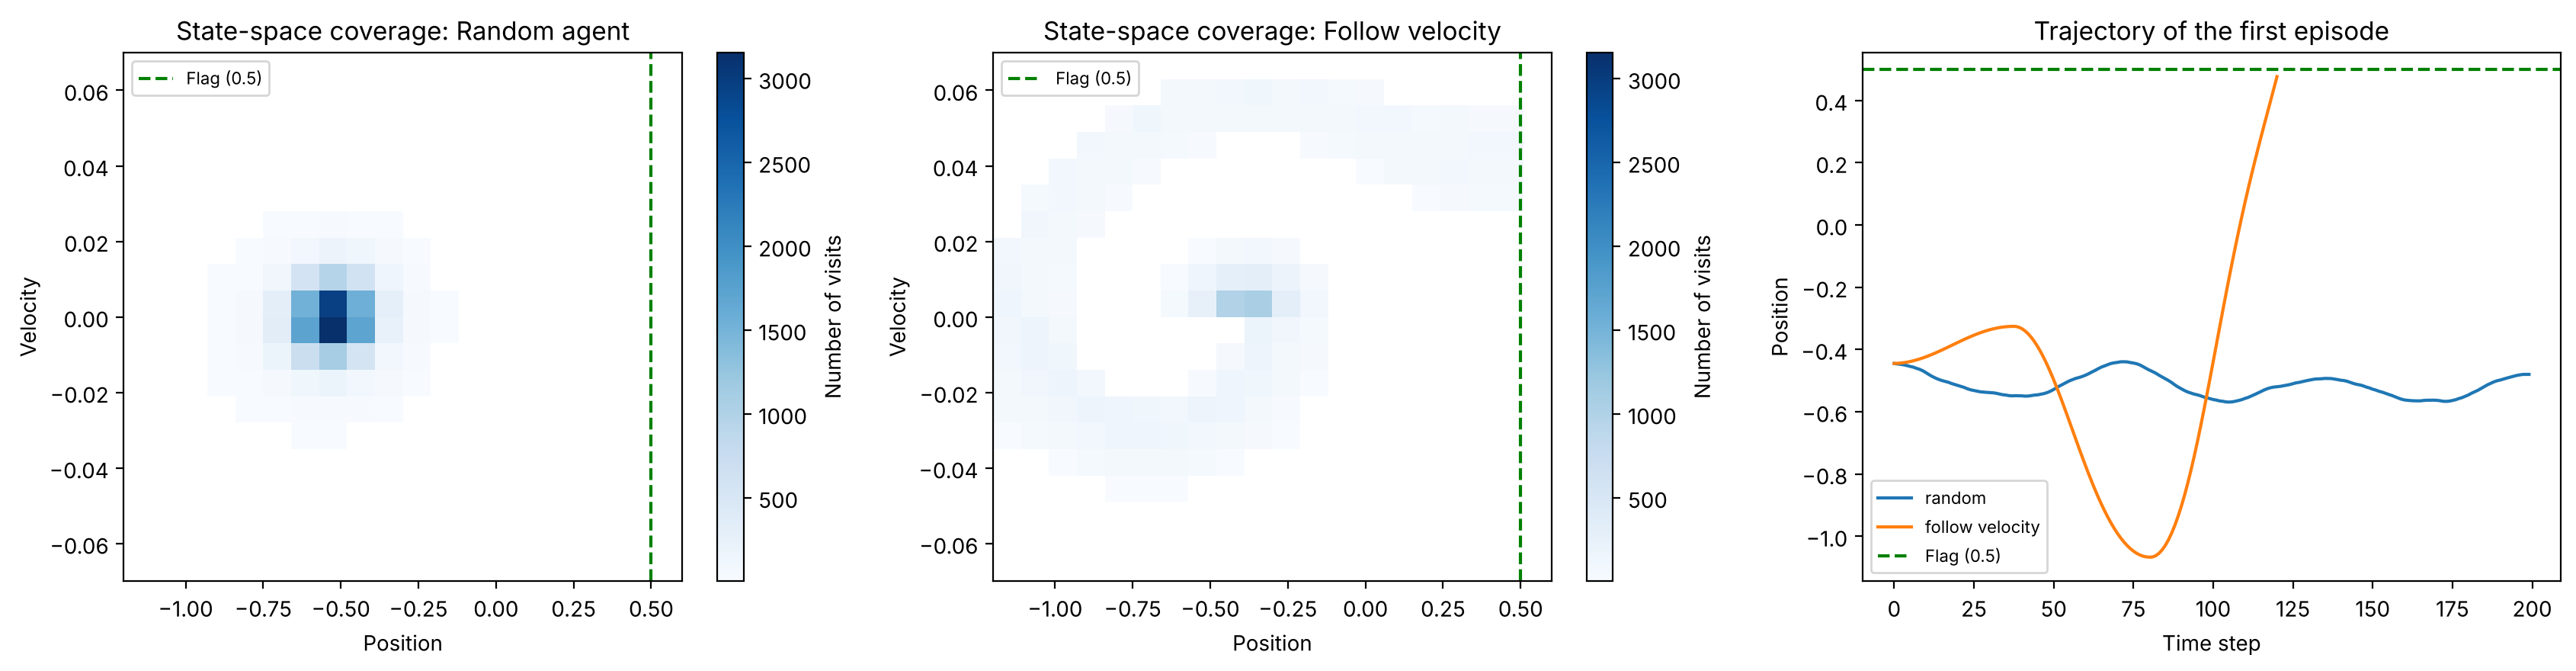

In [10]:
def coverage(d, grid=GRID):
    h, _, _ = np.histogram2d(d["position"], d["velocity"], bins=grid,
                             range=[[low[0], high[0]], [low[1], high[1]]])
    return h, int((h > 0).sum())


h_rand, n_rand = coverage(df)
h_vel, n_vel = coverage(df_velocity)
n_cells = GRID * GRID
print(f"Random agent    : {n_rand} cells visited out of {n_cells} ({100 * n_rand / n_cells:.1f} %)")
print(f"Follow velocity : {n_vel} cells visited out of {n_cells} ({100 * n_vel / n_cells:.1f} %)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
vmax = max(h_rand.max(), h_vel.max())
for ax, h, title in [(axes[0], h_rand, "Random agent"), (axes[1], h_vel, "Follow velocity")]:
    im = ax.imshow(np.ma.masked_equal(h.T, 0), origin="lower", aspect="auto", cmap="Blues",
                   extent=[low[0], high[0], low[1], high[1]], vmin=1, vmax=vmax)
    ax.axvline(ENV_CONST["goal_position"], color="green", linestyle="--", label="Flag (0.5)")
    ax.set_xlabel("Position"); ax.set_ylabel("Velocity")
    ax.set_title(f"State-space coverage: {title}")
    ax.legend(fontsize=8)
    fig.colorbar(im, ax=ax, label="Number of visits")

# Trajectory of the first episode of each policy
for d, name in [(df, "random"), (df_velocity, "follow velocity")]:
    ep0 = d[d["episode"] == 0]
    axes[2].plot(ep0["step"], ep0["position"], label=name)
axes[2].axhline(ENV_CONST["goal_position"], color="green", linestyle="--", label="Flag (0.5)")
axes[2].set_xlabel("Time step"); axes[2].set_ylabel("Position")
axes[2].set_title("Trajectory of the first episode")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/figures/data_acquisition.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.C.6 Saving the dataset

We save the transitions of the random agent (phase 2 dataset) and the per-episode summary of **both** policies (to compare the trained agent with these references later).

In [11]:
df.to_csv("data/transitions_random_agent.csv", index=False)
episodes_all.to_csv("data/baseline_per_episode.csv", index=False)
print("Saved data:")
print(" - data/transitions_random_agent.csv  (", len(df), "transitions )")
print(" - data/baseline_per_episode.csv      (", len(episodes_all), "episodes, 2 policies )")
print(" - requirements.txt                   (versions used)")

Saved data:
 - data/transitions_random_agent.csv  ( 20000 transitions )
 - data/baseline_per_episode.csv      ( 200 episodes, 2 policies )
 - requirements.txt                   (versions used)


### 2.C.7 Summary

The figures below are **computed** from the data: the conclusion relies on them, not on values written in advance.

In [12]:
from IPython.display import Markdown, display

b = baselines.loc["random"]
v = baselines.loc["velocity"]
n_tr = f"{len(df):,}"
# The status of the checks is computed, not asserted
all_ok = all(quality_checks(df).values()) and all(quality_checks(df_velocity).values())
status = "all quality checks of 2.C.2 passed" if all_ok else "⚠️ at least one check of 2.C.2 failed: see above"

display(Markdown(f"""
- **{n_tr}** transitions collected over **{df['episode'].nunique()}** episodes (random agent); {status}.
- **Baseline (random agent)**: mean reward **{b['mean_reward']:.1f}** (standard deviation {b['std_reward']:.1f}), success **{100 * b['success_rate']:.0f} %**, maximal position **{b['max_position']:.3f}** (the flag is at {ENV_CONST['goal_position']}).
- **Benchmark ("follow the velocity" heuristic)**: mean reward **{v['mean_reward']:.1f}**, success **{100 * v['success_rate']:.0f} %**, **{v['mean_steps']:.0f}** steps on average.
- **Coverage**: the random agent visits **{n_rand}** cells out of {n_cells} (**{100 * n_rand / n_cells:.0f} %**) of the {GRID} × {GRID} grid; the heuristic visits **{n_vel}** (**{100 * n_vel / n_cells:.0f} %**).
- **Targets of section 1.5**: beat {b['mean_reward']:.0f} by at least 40 steps (i.e. aim for > {b['mean_reward'] + 40:.0f}), with the official threshold {REWARD_THRESHOLD} as an ambitious goal.
"""))


- **20,000** transitions collected over **100** episodes (random agent); all quality checks of 2.C.2 passed.
- **Baseline (random agent)**: mean reward **-200.0** (standard deviation 0.0), success **0 %**, maximal position **-0.206** (the flag is at 0.5).
- **Benchmark ("follow the velocity" heuristic)**: mean reward **-120.2**, success **100 %**, **120** steps on average.
- **Coverage**: the random agent visits **62** cells out of 400 (**16 %**) of the 20 × 20 grid; the heuristic visits **136** (**34 %**).
- **Targets of section 1.5**: beat -200 by at least 40 steps (i.e. aim for > -160), with the official threshold -110.0 as an ambitious goal.


## Conclusion and next phase

- States are **continuous**: a Q-table cannot store them directly → next phase, **Data Preparation: state discretization**. The number of bins will be chosen **experimentally**, based on the coverage measured in 2.C.5.
- The reward is **always −1** until the flag is reached: the agent receives almost no useful signal at the beginning. This is the main difficulty, which justifies the optimistic initialization of Q and a careful tuning of exploration.
- The **baseline to beat** is the random agent given in the summary 2.C.7. It is complemented by the "follow the velocity" heuristic, which shows that a fast solution exists.
- For the Q update, we will distinguish **`terminated`** (no bootstrap) and **`truncated`** (bootstrap kept), see 2.A.7.

## References

- Moore, A. W. (1990). *Efficient Memory-based Learning for Robot Control*. PhD thesis, University of Cambridge.
- Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning*, 8(3–4), 279–292.
- Rummery, G. A., & Niranjan, M. (1994). *On-line Q-learning using connectionist systems*. Technical report CUED/F-INFENG/TR 166, University of Cambridge.
- Boyan, J. A., & Moore, A. W. (1995). Generalization in reinforcement learning: safely approximating the value function. *Advances in Neural Information Processing Systems 7*.
- Sutton, R. S. (1996). Generalization in reinforcement learning: successful examples using sparse coarse coding. *Advances in Neural Information Processing Systems 8*.
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
- Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature*, 518, 529–533.
- *Modelling a Reinforcement Learning Agent For Mountain Car Problem Using Q-Learning With Tabular Discretization*. IEEE MysuruCon 2022. https://doi.org/10.1109/mysurucon55714.2022.9972352
- Gymnasium documentation – MountainCar-v0: https://gymnasium.farama.org/environments/classic_control/mountain_car/